# Member 2: Data Cleaning and Preprocessing

This notebook performs data cleaning, stratified splitting, imputation, scaling, and SMOTE on the training set only. It exports the processed training and test data. **Model training is intentionally excluded.**

In [1]:
!pip -q install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


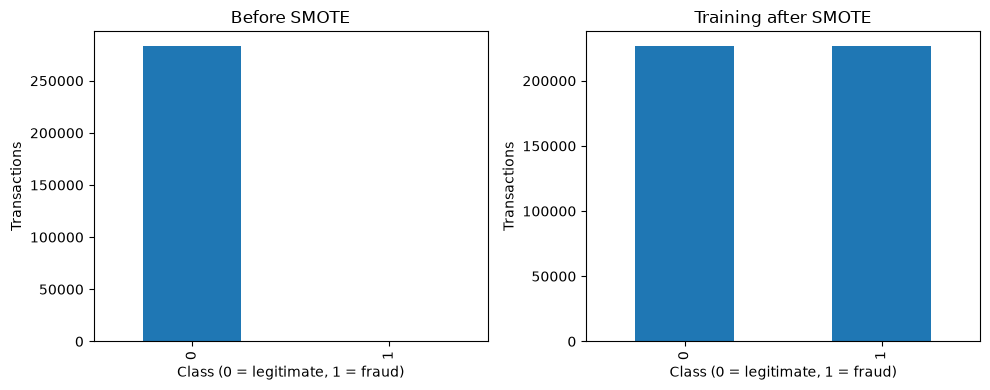

Preprocessing completed successfully.
Original rows: 284,807
Rows removed for missing Class: 0
Duplicate rows removed: 1,081
Balanced training rows: 453,204
Test rows (not resampled): 56,746
Feature count: 30
Training chunks:
  c:\Users\m7129\Desktop\credit-card-fraud-detection\member2_output\member2_train_balanced_part1.csv
  c:\Users\m7129\Desktop\credit-card-fraud-detection\member2_output\member2_train_balanced_part2.csv
  c:\Users\m7129\Desktop\credit-card-fraud-detection\member2_output\member2_train_balanced_part3.csv
Test file: c:\Users\m7129\Desktop\credit-card-fraud-detection\member2_output\member2_test.csv
Reports and graphs: c:\Users\m7129\Desktop\credit-card-fraud-detection\member2_output


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "Class"
BASE_DIR = Path.cwd() # Upload creditcard.csv to this folder in Google Colab.
DATA_PATH = BASE_DIR / "creditcard.csv"
OUTPUT_DIR = BASE_DIR / "member2_output"
REPORT_DIR = OUTPUT_DIR / "reports"
GRAPH_DIR = OUTPUT_DIR / "graphs"
for folder in (OUTPUT_DIR, REPORT_DIR, GRAPH_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Upload creditcard.csv to /content.")

df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError("Dataset must contain a 'Class' column.")
feature_columns = [c for c in df.columns if c != TARGET]
non_numeric = df[feature_columns].select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise ValueError(f"All feature columns must be numeric. Found: {non_numeric}")
if not df[TARGET].dropna().isin([0, 1]).all():
    raise ValueError("Class must contain only 0 (legitimate) and 1 (fraud).")

original_rows = len(df)
missing_target_rows = int(df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET]).copy()
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
df[TARGET] = df[TARGET].astype("int8")
if df[TARGET].nunique() != 2:
    raise ValueError("Both classes must remain after cleaning.")

# Report missing values. Do not delete extreme values: they may be fraud signals.
df.isna().sum().rename("missing_values").to_csv(REPORT_DIR / "missing_values.csv")
X, y = df[feature_columns], df[TARGET]

# Split BEFORE fitting preprocessing steps. Keep the test set separate from SMOTE.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Fit imputation and scaling on training data only to prevent data leakage.
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Apply SMOTE ONLY to the training set. Never resample the test set.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

train_df = pd.DataFrame(X_train_bal, columns=feature_columns)
train_df[TARGET] = np.asarray(y_train_bal, dtype="int8")
test_df = pd.DataFrame(X_test_scaled, columns=feature_columns)
test_df[TARGET] = y_test.to_numpy(dtype="int8")

# Split training CSV into three chunks to make GitHub uploads manageable.
chunk_size = int(np.ceil(len(train_df) / 3))
chunk_paths = []
for part, start in enumerate(range(0, len(train_df), chunk_size), start=1):
    path = OUTPUT_DIR / f"member2_train_balanced_part{part}.csv"
    train_df.iloc[start:start + chunk_size].to_csv(path, index=False)
    chunk_paths.append(path)

test_path = OUTPUT_DIR / "member2_test.csv"
test_df.to_csv(test_path, index=False)

# Record class counts and verify the exported data structure.
summary = pd.DataFrame({
    "stage": ["cleaned_data", "training_before_SMOTE", "training_after_SMOTE", "test_data"],
    "legitimate_0": [int((y == 0).sum()), int((y_train == 0).sum()), int((np.asarray(y_train_bal) == 0).sum()), int((y_test == 0).sum())],
    "fraud_1": [int((y == 1).sum()), int((y_train == 1).sum()), int((np.asarray(y_train_bal) == 1).sum()), int((y_test == 1).sum())]
})
summary.to_csv(REPORT_DIR / "class_distribution.csv", index=False)
assert list(train_df.columns) == list(test_df.columns)
assert set(train_df[TARGET].unique()) == {0, 1}
assert set(test_df[TARGET].unique()) == {0, 1}
assert train_df[TARGET].value_counts().nunique() == 1

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y.value_counts().reindex([0, 1]).plot(kind="bar", ax=axes[0], title="Before SMOTE")
pd.Series(y_train_bal).value_counts().reindex([0, 1]).plot(kind="bar", ax=axes[1], title="Training after SMOTE")
for ax in axes:
    ax.set_xlabel("Class (0 = legitimate, 1 = fraud)")
    ax.set_ylabel("Transactions")
fig.tight_layout()
fig.savefig(GRAPH_DIR / "class_distribution.png", dpi=150)
plt.show()

print("Preprocessing completed successfully.")
print(f"Original rows: {original_rows:,}")
print(f"Rows removed for missing Class: {missing_target_rows:,}")
print(f"Duplicate rows removed: {duplicate_rows:,}")
print(f"Balanced training rows: {len(train_df):,}")
print(f"Test rows (not resampled): {len(test_df):,}")
print(f"Feature count: {len(feature_columns)}")
print("Training chunks:")
for path in chunk_paths:
    print(f"  {path}")
print(f"Test file: {test_path}")
print(f"Reports and graphs: {OUTPUT_DIR}")

## Output files

- `member2_train_balanced_part1.csv`, `part2.csv`, `part3.csv`: balanced training data chunks.
- `member2_test.csv`: original, imbalanced test data.
- `reports/`: missing-value and class-distribution reports.
- `graphs/`: class-distribution chart.

Do not add model training here. The modelling stage should combine the three training chunks and evaluate on `member2_test.csv`.